# Check area-weighted bin mean

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import etunc.config as cfg

In [2]:
PROC_ROOT = cfg.PROC_ROOT
FAMILY = "cmip"
TIME_PERIOD = "199501-201412"
NBINS = "lai15_ai15"
POOL = "qbin_pooled_all"
BIN_VARIABLE = "et_clim"
M = "CESM2.r1i1p1f1"

In [3]:
p = PROC_ROOT / FAMILY / "qbin" / TIME_PERIOD / NBINS

et = {}

f = f"{FAMILY}.{BIN_VARIABLE}.area_weighted.{POOL}.{NBINS}.1deg.{TIME_PERIOD}.nc"
et["aw"] = xr.open_dataset(p / f).et

f = f"{FAMILY}.{BIN_VARIABLE}.{POOL}.{NBINS}.1deg.{TIME_PERIOD}.nc"
et["naw"] = xr.open_dataset(p / f).et

f = f"{FAMILY}.land_area.{POOL}.{NBINS}.1deg.{TIME_PERIOD}.nc"
la = xr.open_dataset(p / f)

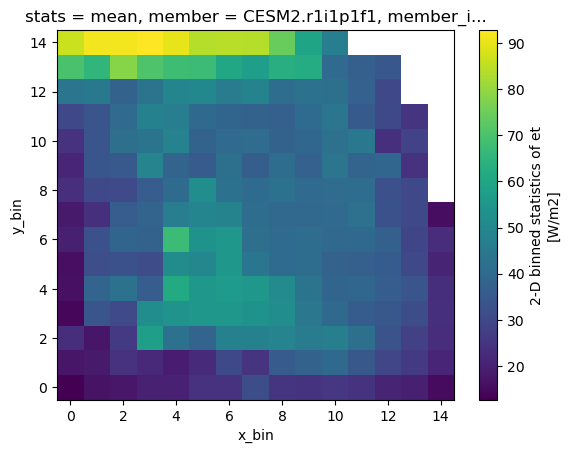

In [4]:
et["naw"].sel(member=M, stats="mean").plot()

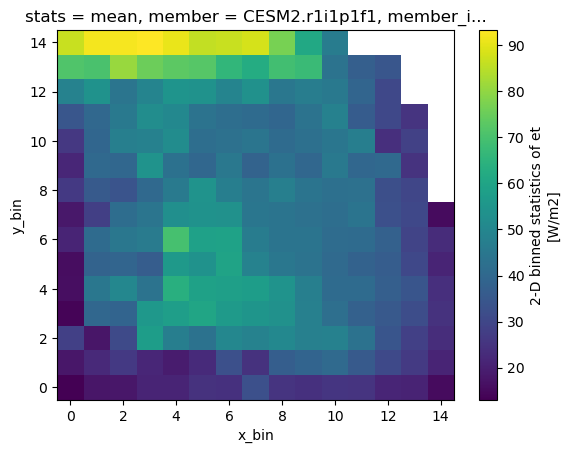

In [9]:
et["aw"].sel(member=M, stats="mean").plot()

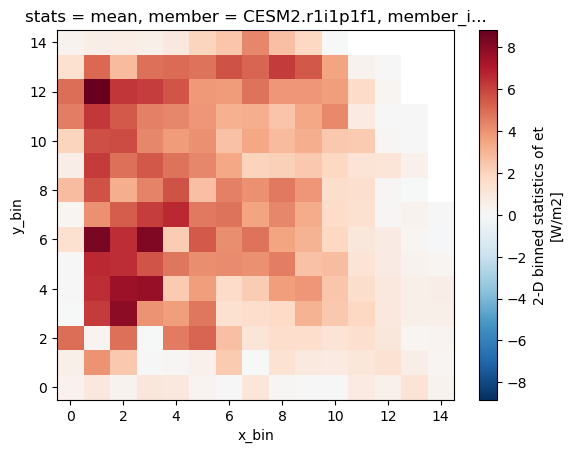

In [8]:
(et["aw"].sel(member=M, stats="mean") - et["naw"].sel(member=M, stats="mean")).plot()

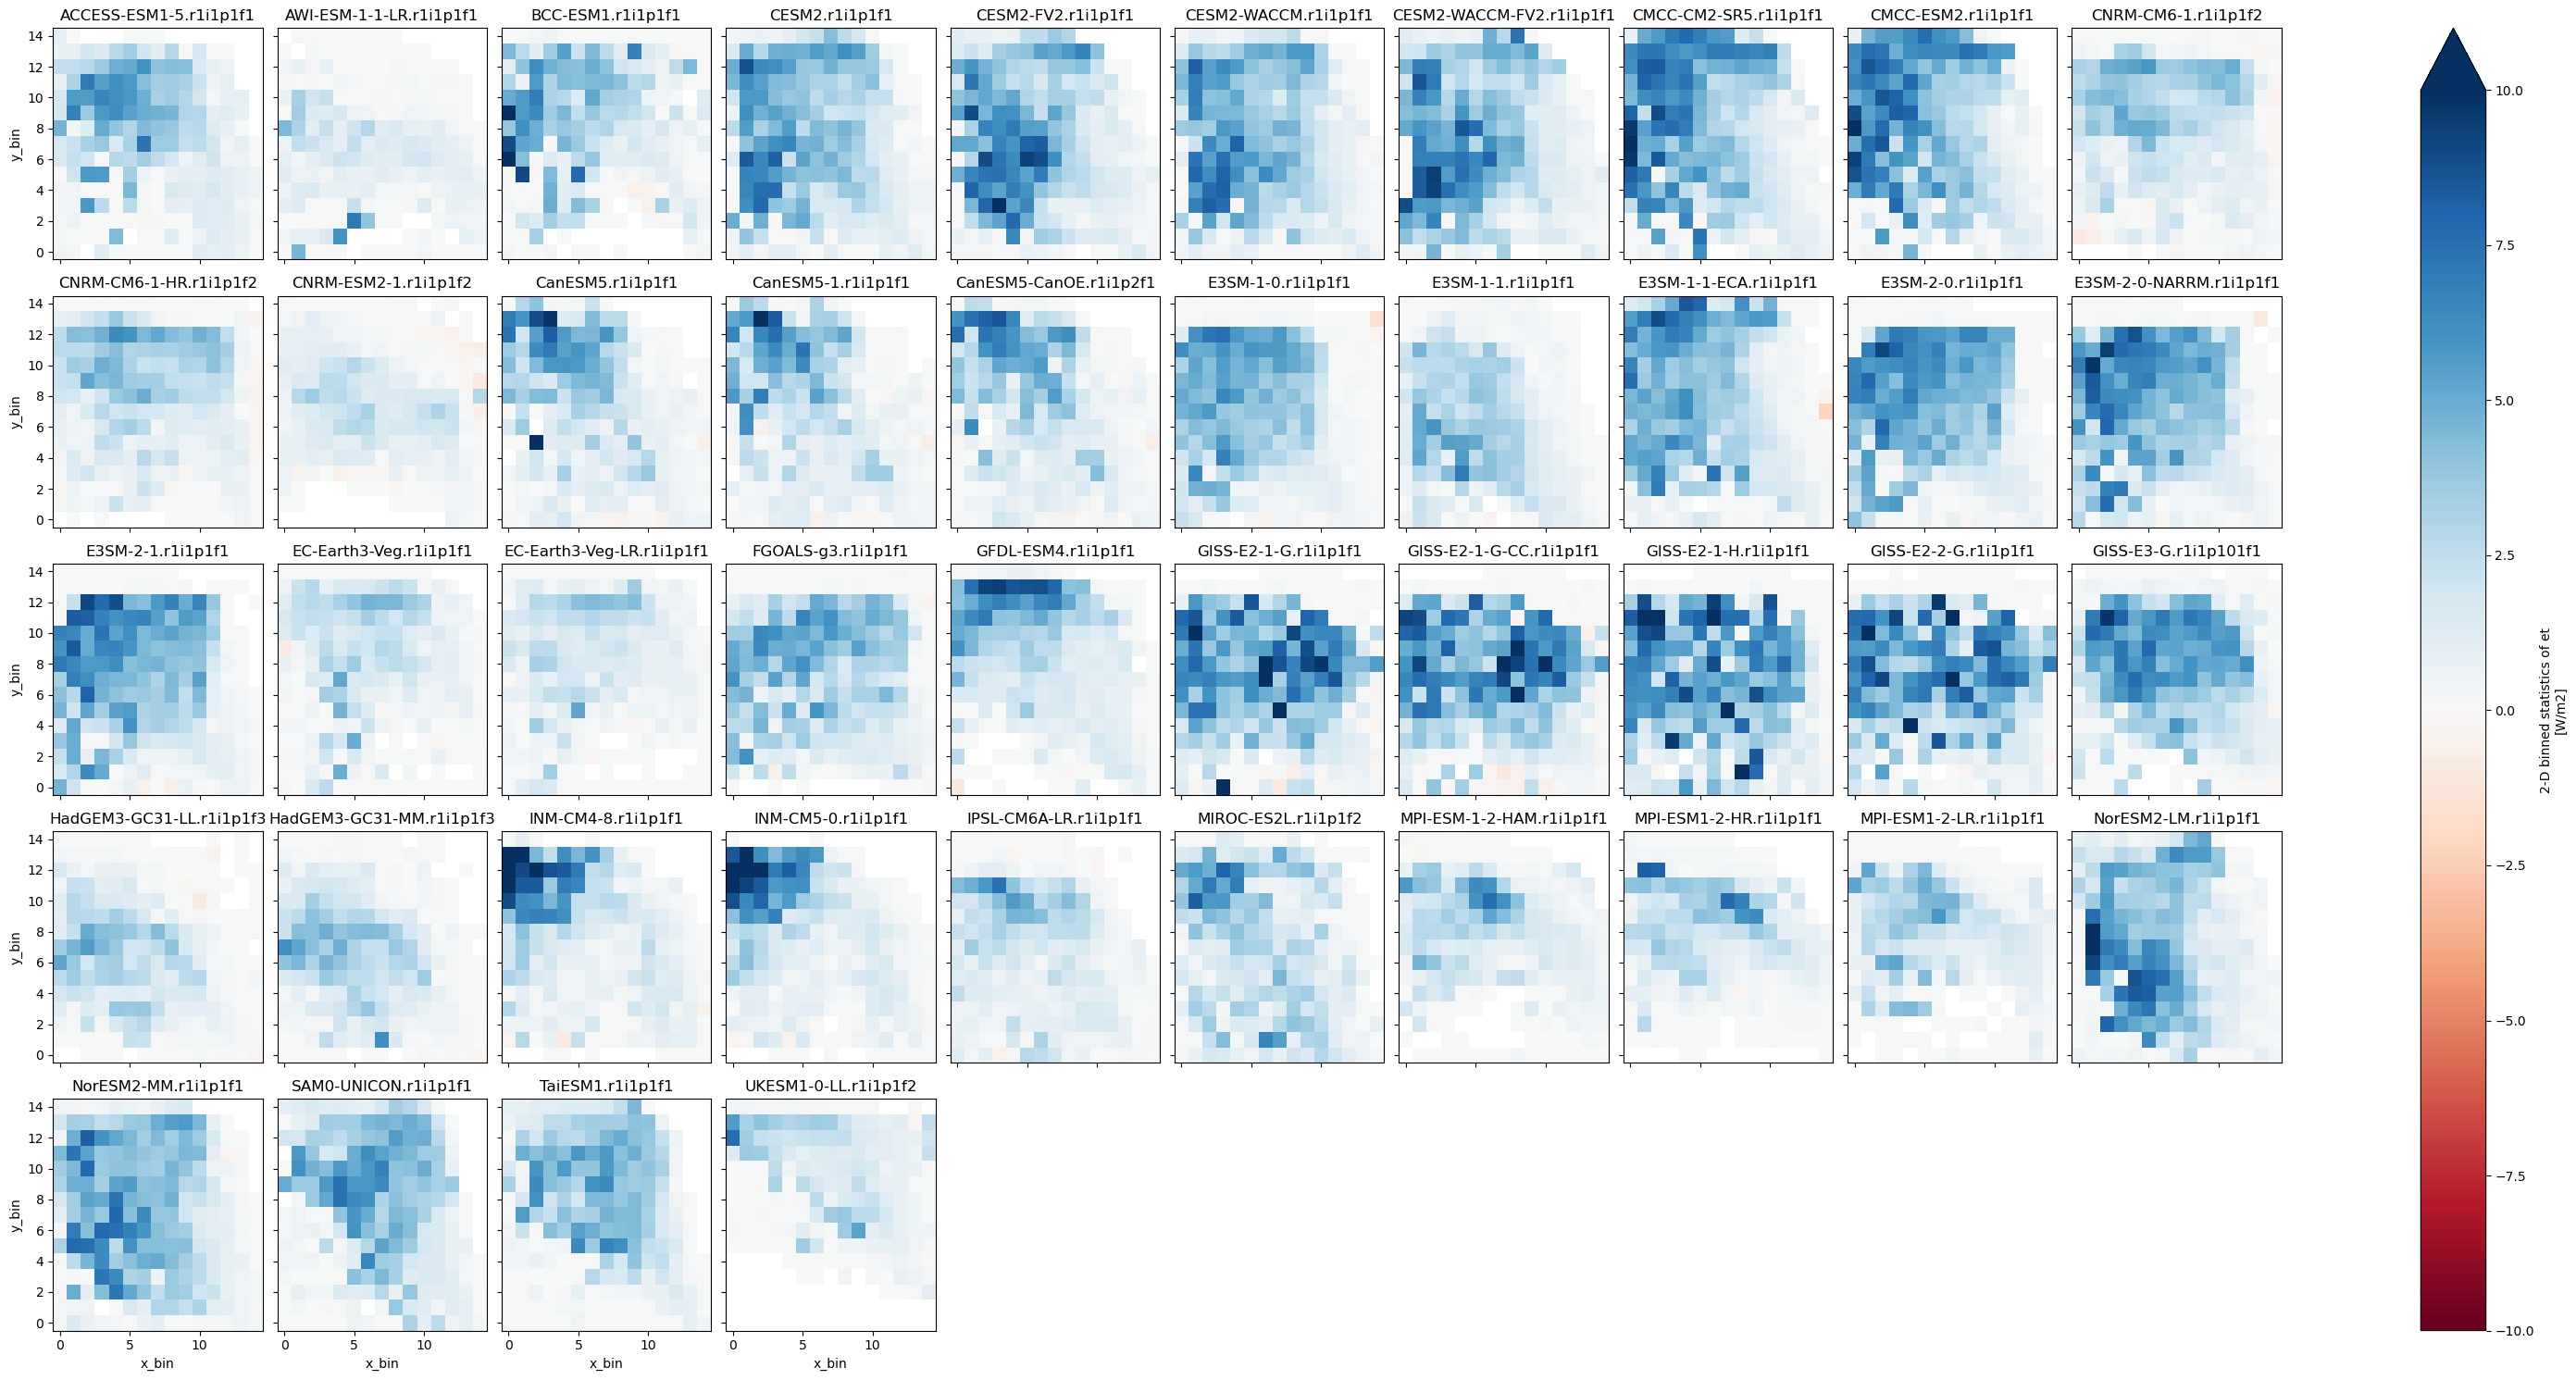

In [15]:
fg = (et["aw"].sel(stats="mean") - et["naw"].sel(stats="mean")).plot(
    col="member", col_wrap=10, vmin=-10, vmax=10, cmap="RdBu")
for ax, m in zip(fg.axs.ravel(), et["aw"].member):
    ax.set_title(m.item())